# Multivariate Time-Series Regression: UCI Appliances Energy Prediction
**Transformer Encoder vs LSTM, kèm phân tích attention map**

Notebook này **không huấn luyện lại**. Nó đọc các file kết quả trong `outputs/` và `data/processed/` rồi tóm tắt toàn bộ bài làm theo thứ tự: bài toán → dữ liệu (EDA) → tiền xử lý → baseline → **toàn bộ quá trình huấn luyện** → đánh giá → attention → kết luận.

**Cách dùng:** chạy xong pipeline (`python -m src.train`, `evaluate`, `attention`, `training_report`) rồi mở notebook này và chọn *Run All*. Nếu thiếu file nào, ô tương ứng sẽ báo "chưa có" chứ không lỗi.

Mục lục: 1 Bài toán · 2 EDA · 3 Tiền xử lý · 4 Baseline · 5 Huấn luyện · 6 Đánh giá · 7 Attention · 7b Ablation nhiệt độ · 8 Kết luận · 9 Câu hỏi hay gặp khi bảo vệ

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook nằm trong notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import load_config, p
from src import training_report as tr

_ov = [f"paths.output_dir={os.environ['ENERGY_TS_OUT']}"] if os.environ.get("ENERGY_TS_OUT") else []
cfg = load_config(overrides=_ov)
OUT, PROC = p(cfg, "output_dir"), p(cfg, "processed_dir")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


def load_json_safe(path):
    path = Path(path)
    return json.load(open(path, encoding="utf-8")) if path.exists() else None


def show_img(path, width=900):
    path = Path(path)
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"(chưa có {path.relative_to(ROOT) if ROOT in path.parents else path})")


def show_csv(path, **kw):
    path = Path(path)
    if path.exists():
        df = pd.read_csv(path, **kw)
        display(df)
        return df
    print(f"(chưa có {path.name})")


def show_md(path):
    path = Path(path)
    if path.exists():
        display(Markdown(path.read_text(encoding="utf-8")))
    else:
        print(f"(chưa có {path.name})")


print("ROOT      :", ROOT)
print("outputs   :", OUT)
print("processed :", PROC)

ROOT      : c:\Users\ADMIN\Desktop\energy_ts
outputs   : C:\Users\ADMIN\Desktop\energy_ts\outputs
processed : C:\Users\ADMIN\Desktop\energy_ts\data\processed


## 1. Bài toán và cấu hình

- **Mục tiêu:** dự đoán mức tiêu thụ điện của thiết bị gia dụng (`Appliances`, đơn vị Wh) từ các chỉ số đa biến quá khứ.
- **Dataset:** UCI *Appliances Energy Prediction*, 1 dòng mỗi 10 phút, hơn 4 tháng, 19.735 dòng.
- **Mô hình chính:** Transformer Encoder cho hồi quy. **Baseline deep learning:** LSTM. **Baseline đơn giản:** persistence, moving average, Ridge.
- **Mở rộng:** so sánh Transformer với LSTM và phân tích attention map.

Bảng bên dưới đọc trực tiếp từ `configs/config.yaml` nên luôn khớp với lần chạy.

In [2]:
H, L = cfg["window"]["horizon"], cfg["window"]["lookback"]
s, tcfg, d = cfg["split"], cfg["train"], cfg["data"]
rows = [
    ("Dataset", "UCI Appliances Energy Prediction"),
    ("Target", f"{d['target_col']} (Wh), 1 điểm / {d['freq_minutes']} phút"),
    ("Bài toán", f"Dự đoán Appliances tại t+{H} (= {H * d['freq_minutes']} phút sau) từ {L} bước quá khứ ({L * d['freq_minutes'] / 60:g} giờ)"),
    ("Chia dữ liệu", f"train/val/test = {s['train']}/{s['val']}/{s['test']}, chia theo thời gian, không shuffle"),
    ("Biến đổi target", d["target_transform"]),
    ("Feature", "toàn bộ cảm biến + lịch sử Appliances + giờ/thứ (sin/cos); bỏ " + ", ".join(d["drop_cols"])),
    ("Transformer", ", ".join(f"{k}={v}" for k, v in cfg["transformer"].items())),
    ("LSTM", ", ".join(f"{k}={v}" for k, v in cfg["lstm"].items())),
    ("Huấn luyện", f"AdamW lr={tcfg['lr']}, batch={tcfg['batch_size']}, loss={tcfg['loss']}, tối đa {tcfg['epochs']} epoch, "
                    f"early stopping patience={tcfg['patience']} (theo val RMSE bằng Wh), seeds={tcfg['seeds']}"),
    ("Metric chính", "RMSE (Wh) trên test; phụ: MAE, MAPE, sMAPE, R²"),
]
display(pd.DataFrame(rows, columns=["Mục", "Giá trị"]))

,Mục,Giá trị
0,Dataset,UCI Appliances Energy Prediction
1,Target,"Appliances (Wh), 1 điểm / 10 phút"
2,Bài toán,Dự đoán Appliances tại t+6 (= 60 phút sau) từ 36 bước quá khứ (6 giờ)
3,Chia dữ liệu,"train/val/test = 0.7/0.15/0.15, chia theo thời gian, không shuffle"
4,Biến đổi target,log1p
5,Feature,"toàn bộ cảm biến + lịch sử Appliances + giờ/thứ (sin/cos); bỏ rv1, rv2"
6,Transformer,"d_model=64, nhead=4, num_layers=2, dim_ff=128, dropout=0.1, pooling=cls"
7,LSTM,"hidden=64, num_layers=2, dropout=0.1"
8,Huấn luyện,"AdamW lr=0.001, batch=128, loss=mse, tối đa 100 epoch, early stopping patience=12 (theo val RMSE bằng Wh), seeds=[0, 1, 2]"
9,Metric chính,"RMSE (Wh) trên test; phụ: MAE, MAPE, sMAPE, R²"


**Các quyết định đã chốt và lý do** (chi tiết ở `doc/11_decisions_log.md`)

| Quyết định | Lý do |
|---|---|
| PyTorch | lấy attention weights dễ |
| Dự đoán t+6 (1 giờ) | khó hơn t+1 và có ý nghĩa thực tế hơn |
| Chia theo thời gian, scaler fit chỉ trên train | tránh rò rỉ dữ liệu tương lai |
| `log1p` cho target | target lệch phải mạnh (skew 3.39 → 1.19) |
| Loss MSE | khớp với metric RMSE; Huber chỉ là đối chứng |
| `lookback = 36` | ACF cho thấy phụ thuộc ngắn hạn mạnh, lag 36 gần 0 |
| 3 seed, báo cáo mean ± std | giảm nhiễu do khởi tạo |
| Bắt buộc vượt Ridge (V3) | persistence có R² âm trên test nên là mốc quá dễ |

## 2. EDA: dữ liệu trông như thế nào
Phần này đọc kết quả của `python -m src.eda`.

In [3]:
show_md(OUT / "eda" / "eda_summary.md")

# EDA summary (tự sinh bởi `python -m src.eda`)

- Số dòng: **19735**, giai đoạn 2016-01-11 17:00:00 -> 2016-05-27 18:00:00
- Thiếu: 0 ô | timestamp trùng: 0 | bước thời gian không đều: 0
- Target `Appliances`: mean=97.7, median=60.0, std=102.5, min=10, max=1080, P99=577, skew=3.39
- Giờ cao điểm: 18h; giờ thấp nhất: 3h (tỉ lệ 3.95x)
- ACF: lag_1=0.75, lag_3=0.44, lag_6=0.32, lag_36=0.02, lag_144=0.22
- Top feature theo |corr(feature[t], target[t+H])|: RH_out=-0.13, lights=0.12, T6=0.12, Windspeed=0.09, T_out=0.09
- Persistence trên đoạn test (t -> t+6): RMSE=101.8 Wh, R2=-0.252 (mốc tối thiểu mà mô hình phải vượt)

## Phát hiện & gợi ý quyết định

1. Target lệch phải mạnh (skew=3.39; sau log1p còn 1.19) -> cân nhắc `data.target_transform: log1p` (quyết định mở D3).
2. 10.8% điểm là outlier theo IQR; đây là các đỉnh tiêu thụ thật, KHÔNG nên xoá. Dùng loss Huber là một lựa chọn (quyết định mở D4).
3. rv1/rv2 gần như không tương quan với target -> giữ trong `drop_cols`.
4. `lights` bằng 0 ở 77% số dòng (biến rời rạc, nhiều số 0).
5. Có drift giữa train và test (lớn nhất 3.14 std) -> mô hình có thể giảm hiệu năng ở test; ghi vào báo cáo kết quả.

Hình: `target_distribution.png`, `target_timeseries.png`, `daily_weekly_profile.png`, `acf_target.png`, `correlation_heatmap.png`, `target_correlation_top.png`, `feature_distributions.png`, `split_drift.png`.

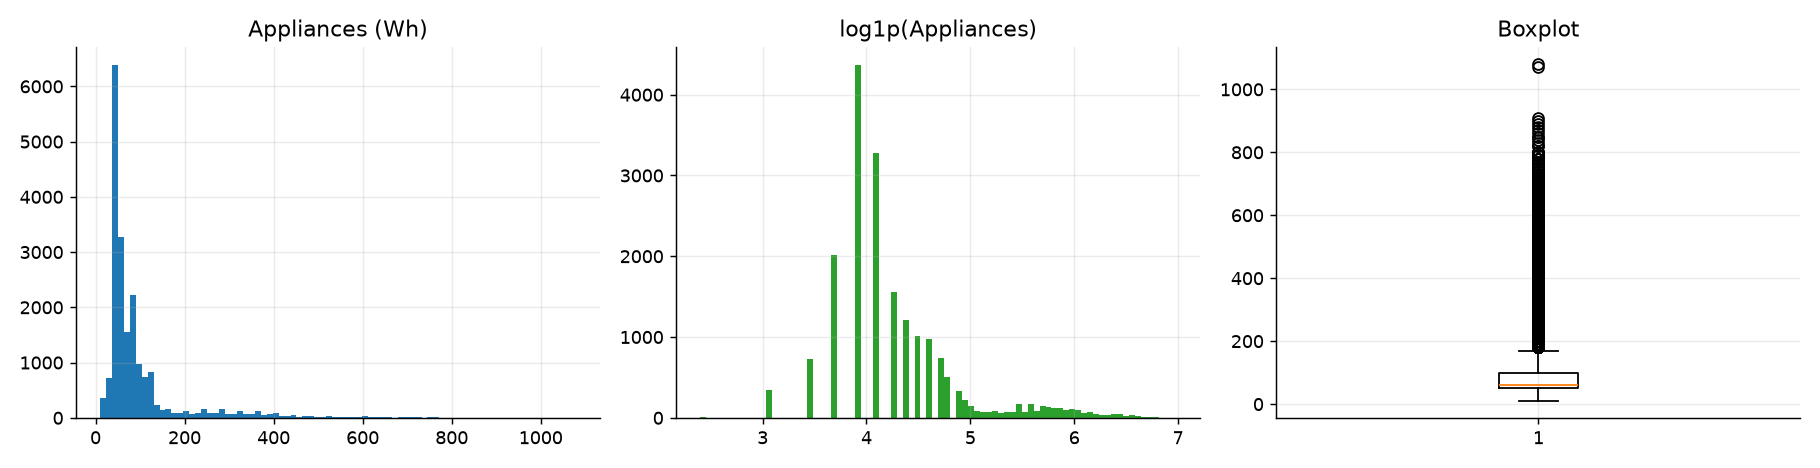

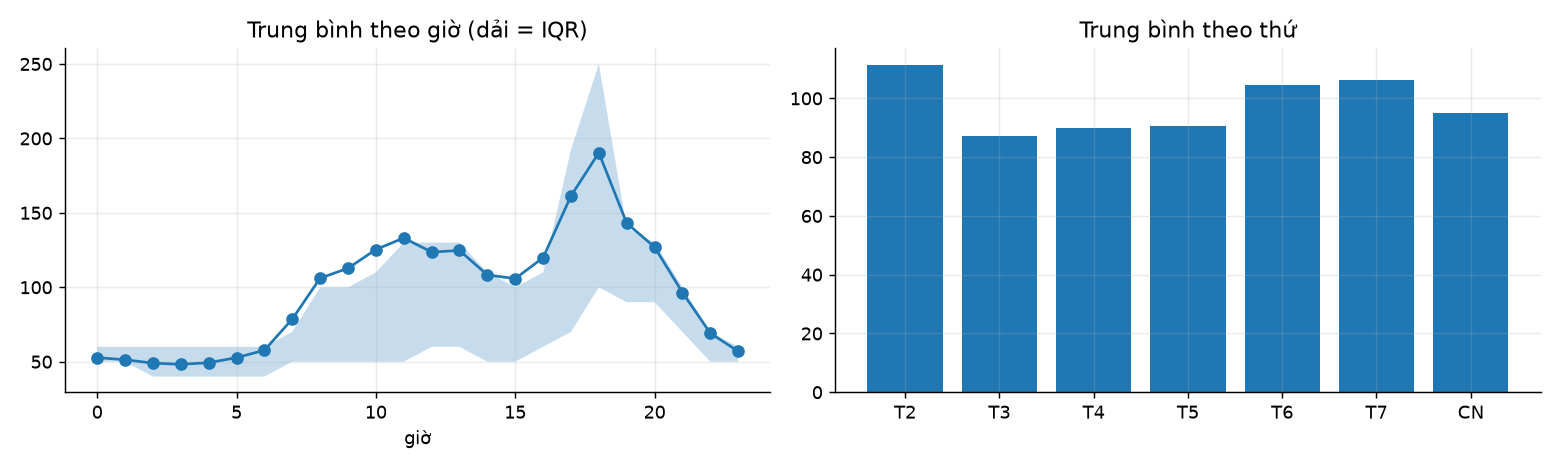

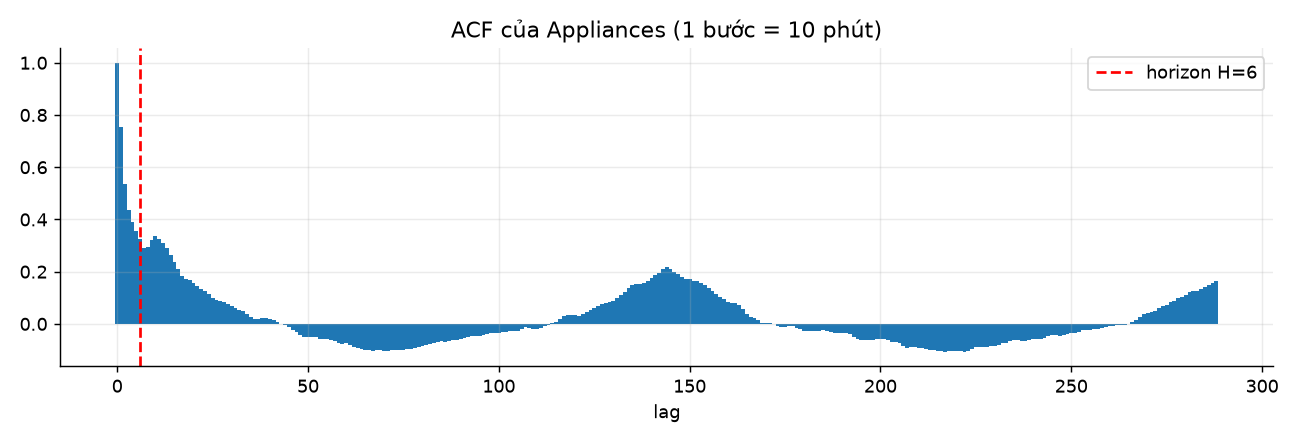

In [4]:
for name in ["target_distribution.png", "daily_weekly_profile.png", "acf_target.png"]:
    show_img(OUT / "eda" / name, width=950)

**Điều cần rút ra từ EDA**
- Target lệch phải mạnh, có nhiều đỉnh đột biến (khoảng 10% điểm là outlier theo IQR). Đó là đỉnh tiêu thụ thật nên không xoá.
- Có chu kỳ ngày rõ rệt (cao điểm buổi tối, thấp nhất rạng sáng) nên có feature giờ/thứ.
- ACF giảm nhanh sau vài bước: một giờ sau thì tương quan với hiện tại chỉ còn khoảng 0.3, đây là lý do bài toán khó.
- Test rơi vào giai đoạn ấm hơn train (xem hình drift bên dưới).

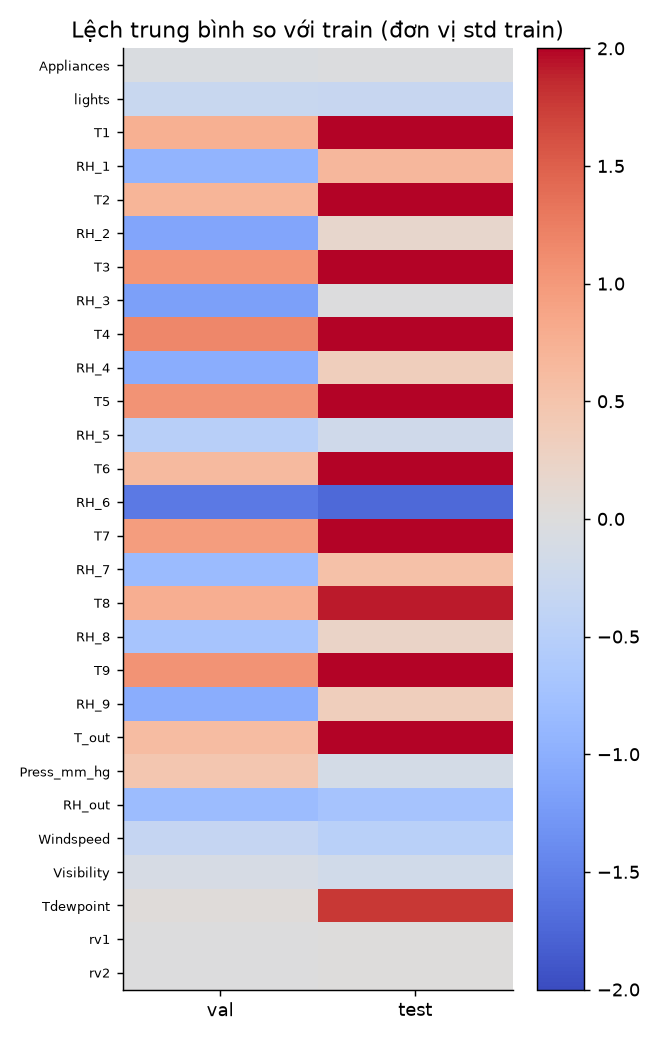

Các biến lệch nhiều nhất giữa test và train (đơn vị: độ lệch chuẩn của train):


,lệch ở test
T9,3.14
T5,3.05
T4,2.89
T3,2.82
T7,2.80
T2,2.70
T1,2.55
T6,2.17


In [5]:
show_img(OUT / "eda" / "split_drift.png", width=520)
drift = pd.read_csv(OUT / "eda" / "split_drift_zscore.csv", index_col=0) if (OUT / "eda" / "split_drift_zscore.csv").exists() else None
if drift is not None:
    print("Các biến lệch nhiều nhất giữa test và train (đơn vị: độ lệch chuẩn của train):")
    display(drift["test"].sort_values(key=np.abs, ascending=False).head(8).round(2).to_frame("lệch ở test"))

## 3. Tiền xử lý
Các bước (`python -m src.preprocess`): đọc và kiểm tra → bỏ `rv1`, `rv2` → biến đổi target → thêm feature thời gian → chia theo thời gian → fit scaler chỉ trên train → cắt cửa sổ trượt → kiểm tra chống rò rỉ.

,giai đoạn,số window
train,2016-01-11T17:00:00 → 2016-04-16T15:10:00,13773
val,2016-04-16T15:20:00 → 2016-05-07T04:30:00,2960
test,2016-05-07T04:40:00 → 2016-05-27T18:00:00,2961


Lookback L=36, horizon H=6, số feature F=31, target_transform=none


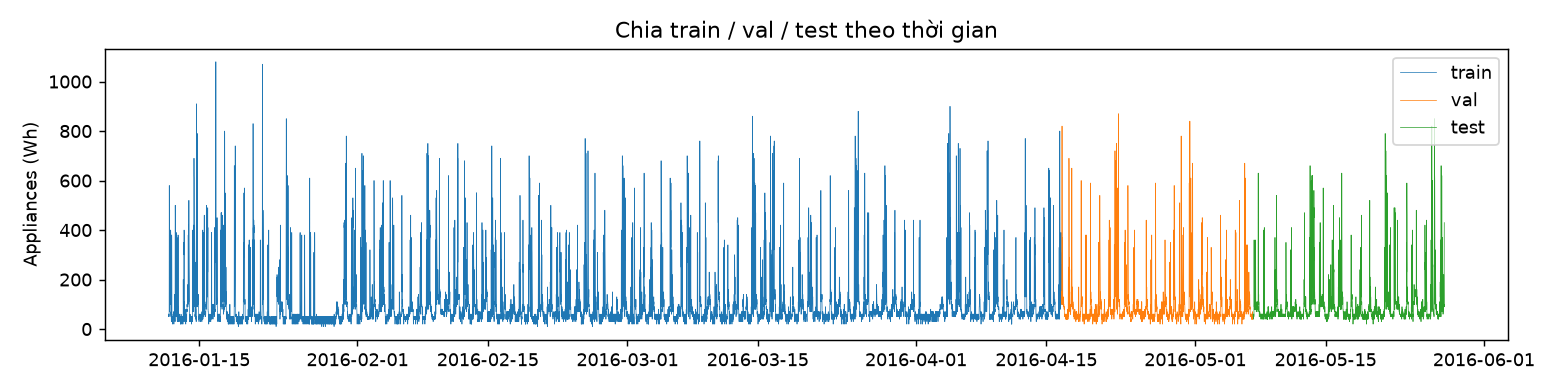

In [6]:
info = load_json_safe(PROC / "split_info.json")
if info:
    tbl = pd.DataFrame({
        "giai đoạn": [info["train_period"][0] + "  →  " + info["train_period"][1],
                      info["val_period"][0] + "  →  " + info["val_period"][1],
                      info["test_period"][0] + "  →  " + info["test_period"][1]],
        "số window": [info["n_windows"]["train"], info["n_windows"]["val"], info["n_windows"]["test"]]},
        index=["train", "val", "test"])
    display(tbl)
    feats = load_json_safe(PROC / "feature_names.json") or []
    sc = load_json_safe(PROC / "scaler.json") or {}
    print(f"Lookback L={info['lookback']}, horizon H={info['horizon']}, số feature F={len(feats)}, target_transform={sc.get('target_transform')}")
else:
    print("(chưa có split_info.json, hãy chạy python -m src.preprocess)")
show_img(PROC / "split_timeline.png", width=950)

## 4. Baseline (không dùng deep learning)
Đây là các mốc mà mô hình deep learning phải vượt. **Ridge là mốc có ý nghĩa nhất:** persistence có R² âm trên test, nghĩa là còn kém cả việc luôn đoán một giá trị trung bình, nên vượt persistence là mốc quá dễ.

In [7]:
b = show_csv(OUT / "baselines" / "summary.csv", index_col=0)

,rmse,mae,mape,smape,r2,n
persistence,101.658486,46.291793,38.148504,31.034391,-0.251452,2961.0
moving_avg_6,88.255639,42.806484,37.522316,30.981537,0.056782,2961.0
moving_avg_all,89.772175,48.809899,48.505320,39.338107,0.024088,2961.0
daily_naive,109.473271,52.489024,48.829960,37.122009,-0.451253,2961.0
ridge,81.723461,49.117377,53.771505,41.892221,0.191238,2961.0


## 5. Toàn bộ quá trình huấn luyện

### 5.1 Cách huấn luyện và vì sao dừng sớm
Mỗi (mô hình, seed) được huấn luyện độc lập. Sau **mỗi epoch** ta đo val RMSE (đơn vị Wh) rồi quyết định:

1. **Lưu checkpoint tốt nhất:** nếu val RMSE giảm hơn mức tốt nhất trước đó (ngưỡng 1e-6) thì lưu trọng số này và đặt lại bộ đếm chờ.
2. **Đếm epoch không cải thiện:** nếu không cải thiện, bộ đếm tăng thêm 1.
3. **Early stopping:** khi bộ đếm đạt `patience` (ở đây 12) thì dừng. Mô hình cuối cùng được dùng là checkpoint của **epoch tốt nhất**, không phải epoch cuối.
4. **Giảm learning rate:** song song, `ReduceLROnPlateau` nhân lr với 0.5 khi val RMSE không cải thiện trong một số epoch ngắn hơn patience, để mô hình có cơ hội cải thiện thêm trước khi bị dừng.

Lý do dừng sớm: sau một điểm nào đó, train loss vẫn giảm nhưng val RMSE đi ngang hoặc tăng. Đó là mô hình bắt đầu học thuộc dữ liệu train (overfit). Dừng ở đây vừa tiết kiệm thời gian vừa giữ được mô hình tổng quát hoá tốt nhất trên val.

In [8]:
show_csv(OUT / "models" / "train_summary_all.csv")

,model,seed,n_params,best_epoch,epochs_run,best_val_rmse_wh,train_seconds,device
0,transformer,5,73409,11,15,80.905445,149.1,cpu


,model,seed,n_params,best_epoch,epochs_run,best_val_rmse_wh,train_seconds,device
0,transformer,5,73409,11,15,80.905445,149.1,cpu


### 5.2 Tất cả các run trên cùng một biểu đồ
Màu đỏ là Transformer, màu xanh là LSTM, kiểu nét phân biệt seed. Trên đồ thị giữa: **chấm đen viền = epoch tốt nhất**, **dấu ✕ = điểm dừng**. Hai đường chấm xám là val RMSE của Ridge và moving_avg_6, dùng để xem mô hình đã vượt mốc chưa.

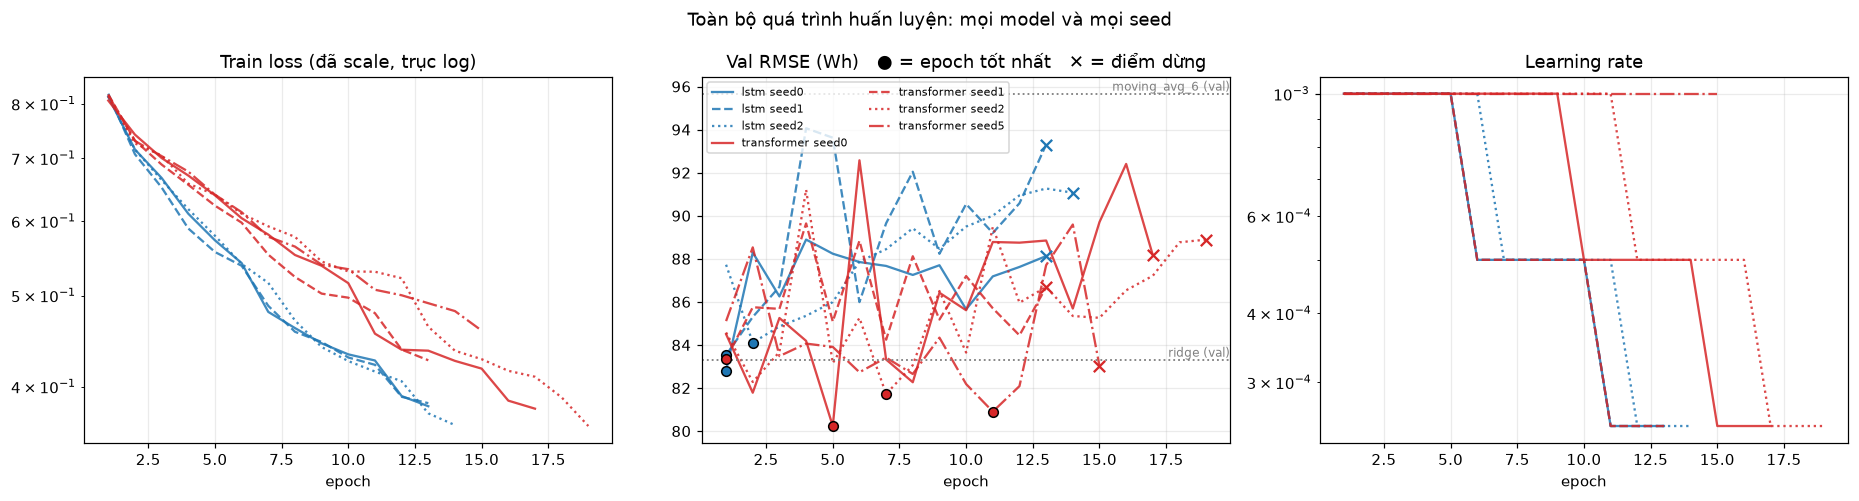

In [9]:
runs = tr.load_runs(cfg)
refs = tr.reference_lines(cfg)
if runs:
    fig = tr.plot_overview(runs, refs)
    plt.show()
else:
    print("Chưa có history.csv. Hãy chạy python -m src.train trước.")

### 5.3 Từng run riêng lẻ
Hàng trên là LSTM, hàng dưới là Transformer (nếu đủ), mỗi cột là một seed. Đường xanh lá là train loss (trục trái, log), đường màu là val RMSE (trục phải). Đường đứt dọc là epoch tốt nhất; **vùng cam là các epoch chờ cải thiện** cho tới khi early stopping kích hoạt.

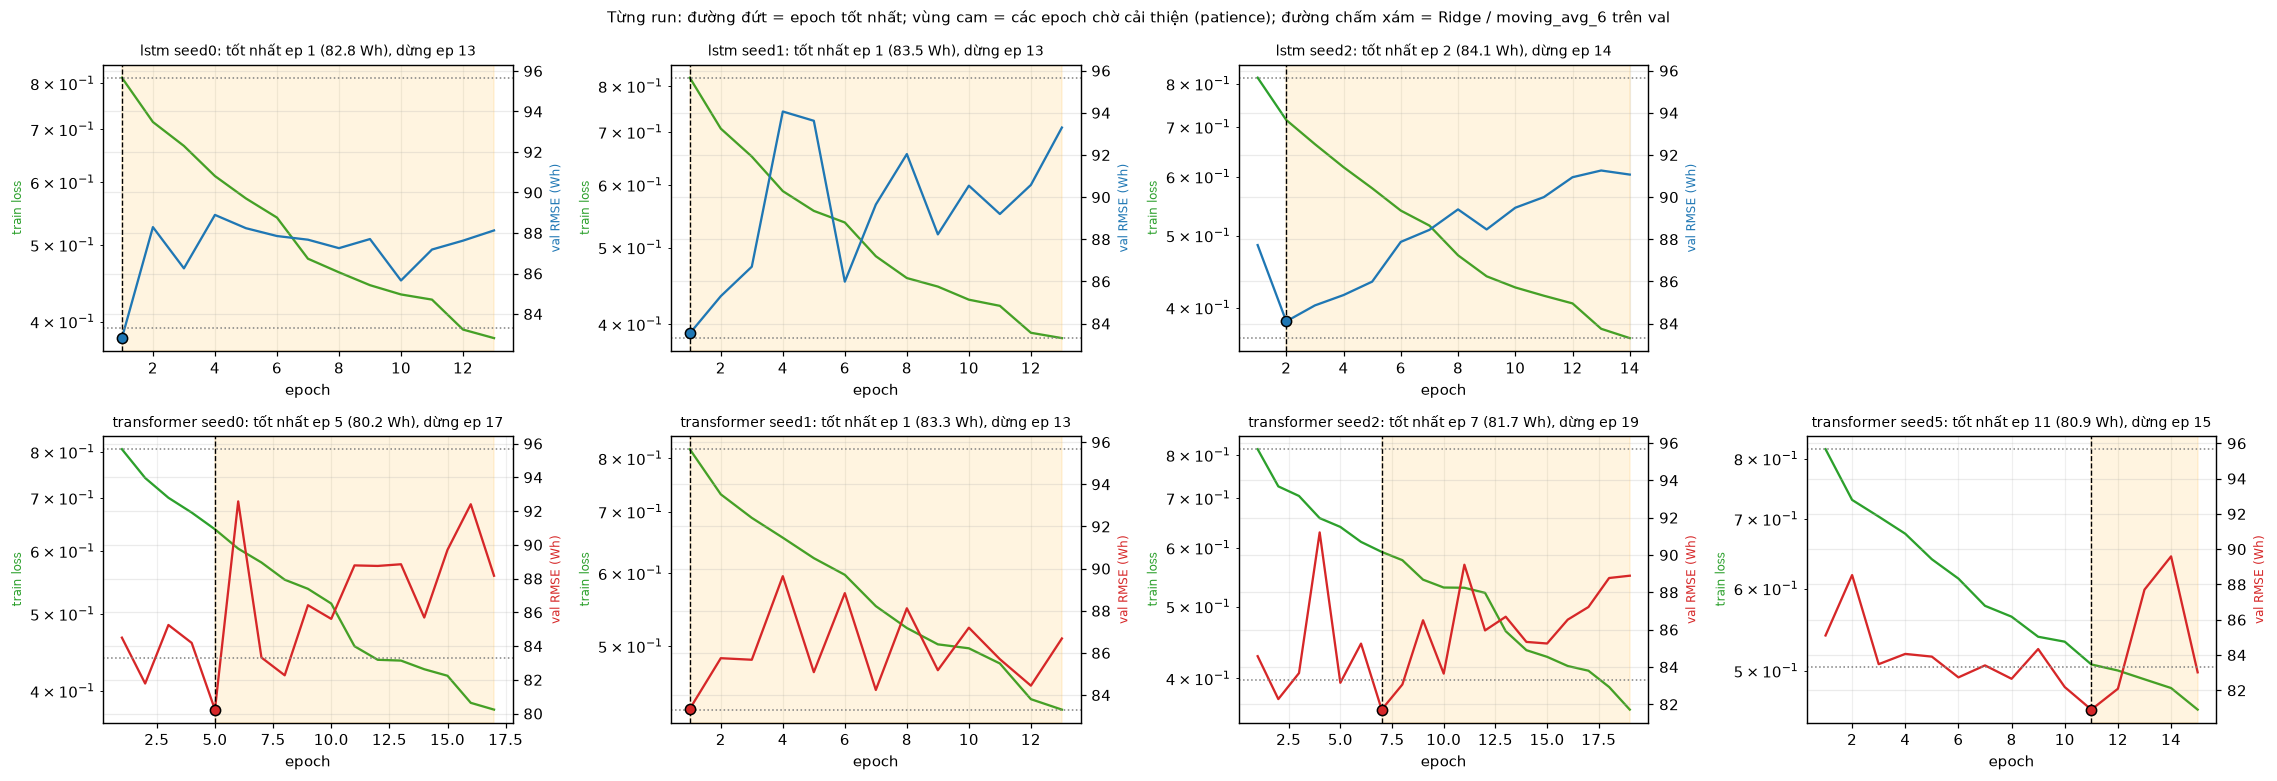

In [10]:
if runs:
    fig = tr.plot_per_run(runs, refs)
    plt.show()

### 5.4 Bảng tóm tắt và lý do dừng của từng run

In [11]:
if runs:
    tbl = tr.runs_table(runs)
    cols = ["model", "seed", "epochs_chạy", "epoch_tốt_nhất", "val_RMSE_epoch1", "val_RMSE_tốt_nhất",
            "cải_thiện_so_với_epoch1", "lần_giảm_lr", "thời_gian_s", "n_params"]
    display(tbl[cols])
    print()
    for _, r in tbl.iterrows():
        print(f"- {r['model']} {r['seed']}: {r['lý_do_dừng']}.  Nhận xét: {r['nhận_xét']}.")

,model,seed,epochs_chạy,epoch_tốt_nhất,val_RMSE_epoch1,val_RMSE_tốt_nhất,cải_thiện_so_với_epoch1,lần_giảm_lr,thời_gian_s,n_params
0,lstm,seed0,13,1,82.81,82.81,0.00,2,33.1,62337
1,lstm,seed1,13,1,83.53,83.53,0.00,2,33.1,62337
2,lstm,seed2,14,2,87.73,84.11,3.62,2,35.3,62337
3,transformer,seed0,17,5,84.50,80.24,4.26,2,128.4,73409
4,transformer,seed1,13,1,83.34,83.34,0.00,2,94.7,73409
5,transformer,seed2,19,7,84.58,81.72,2.86,2,139.3,73409
6,transformer,seed5,15,11,85.11,80.91,4.20,0,149.1,73409



- lstm seed0: Early stopping: val RMSE không cải thiện 12 epoch liên tiếp (tốt nhất ở epoch 1, dừng ở epoch 13).  Nhận xét: Val RMSE có xu hướng TĂNG sau epoch tốt nhất trong khi train loss vẫn giảm: nghi overfit.
- lstm seed1: Early stopping: val RMSE không cải thiện 12 epoch liên tiếp (tốt nhất ở epoch 1, dừng ở epoch 13).  Nhận xét: Val RMSE có xu hướng TĂNG sau epoch tốt nhất trong khi train loss vẫn giảm: nghi overfit.
- lstm seed2: Early stopping: val RMSE không cải thiện 12 epoch liên tiếp (tốt nhất ở epoch 2, dừng ở epoch 14).  Nhận xét: Val RMSE có xu hướng TĂNG sau epoch tốt nhất trong khi train loss vẫn giảm: nghi overfit.
- transformer seed0: Early stopping: val RMSE không cải thiện 12 epoch liên tiếp (tốt nhất ở epoch 5, dừng ở epoch 17).  Nhận xét: Val RMSE có xu hướng TĂNG sau epoch tốt nhất trong khi train loss vẫn giảm: nghi overfit.
- transformer seed1: Early stopping: val RMSE không cải thiện 12 epoch liên tiếp (tốt nhất ở epoch 1, dừng ở epoch 13).  Nhận xét: Val R

In [12]:
if runs:
    t = tbl.copy()
    t["thời_gian_s"] = pd.to_numeric(t["thời_gian_s"], errors="coerce")
    g = t.groupby("model").agg(
        số_run=("seed", "count"), epochs_TB=("epochs_chạy", "mean"), epoch_tốt_nhất_TB=("epoch_tốt_nhất", "mean"),
        val_RMSE_TB=("val_RMSE_tốt_nhất", "mean"), val_RMSE_std=("val_RMSE_tốt_nhất", "std"),
        thời_gian_TB_s=("thời_gian_s", "mean")).round(2)
    display(g)
    n_es = int(t["lý_do_dừng"].str.startswith("Early").sum())
    n_max = int(t["lý_do_dừng"].str.startswith("Hết").sum())
    print(f"\n{n_es}/{len(t)} run dừng do early stopping; {n_max}/{len(t)} run chạy hết số epoch tối đa.")
    if n_max:
        print("Các run chạy hết epoch tối đa có thể còn cải thiện nếu tăng train.epochs.")
    print("Epoch tốt nhất xuất hiện sớm nhất / muộn nhất:", int(t["epoch_tốt_nhất"].min()), "/", int(t["epoch_tốt_nhất"].max()))

,số_run,epochs_TB,epoch_tốt_nhất_TB,val_RMSE_TB,val_RMSE_std,thời_gian_TB_s
model,,,,,,
lstm,3,13.33,1.33,83.48,0.65,33.83
transformer,4,16.00,6.00,81.55,1.34,127.88



6/7 run dừng do early stopping; 1/7 run chạy hết số epoch tối đa.
Các run chạy hết epoch tối đa có thể còn cải thiện nếu tăng train.epochs.
Epoch tốt nhất xuất hiện sớm nhất / muộn nhất: 1 / 11


**Cách đọc phần huấn luyện**
- Train loss giảm đều là bình thường. Điều đáng quan sát là val RMSE: nếu nó giảm rồi đi ngang, mô hình đã bão hoà; nếu tăng trong khi train loss vẫn giảm, đó là overfit.
- Số epoch tốt nhất thường nhỏ hơn nhiều so với 100 epoch tối đa, nên early stopping là cần thiết và không tốn công vô ích.
- Dao động của val RMSE giữa các epoch cho thấy tín hiệu rất nhiễu (dataset khó). Vì vậy kết quả được báo cáo qua nhiều seed chứ không dựa vào một lần chạy.
- Các lần giảm learning rate (đồ thị bên phải ở hình 5.2) là lúc mô hình bị kẹt và được thử với bước nhỏ hơn.

## 6. Đánh giá trên tập test (đơn vị Wh)
`python -m src.evaluate`. Test chỉ được dùng để báo cáo, không dùng để chỉnh siêu tham số.

In [13]:
sm = OUT / "metrics" / "summary.csv"
if sm.exists():
    df = pd.read_csv(sm)
    show = df[["model", "kind", "n_seeds", "n_params", "rmse_mean", "rmse_std", "mae_mean", "mape_mean", "r2_mean"]].round(3)
    display(show)
else:
    print("(chưa có outputs/metrics/summary.csv, hãy chạy python -m src.evaluate)")

,model,kind,n_seeds,n_params,rmse_mean,rmse_std,mae_mean,mape_mean,r2_mean
0,persistence,baseline,1,0,101.658,0.000,46.292,38.149,-0.251
1,moving_avg_6,baseline,1,0,88.256,0.000,42.806,37.522,0.057
2,ridge,baseline,1,0,81.723,0.000,49.117,53.772,0.191
3,transformer,deep,3,73409,82.390,2.561,45.144,46.866,0.177
4,transformer_seed_ensemble,deep_ensemble,3,73409,79.719,0.000,43.952,45.692,0.230
5,lstm,deep,3,62337,87.517,3.807,52.743,57.973,0.071
6,lstm_seed_ensemble,deep_ensemble,3,62337,83.332,0.000,49.777,54.856,0.159


### So sánh có ý nghĩa thống kê (block bootstrap)
ΔRMSE = RMSE(a) − RMSE(b). Âm nghĩa là a tốt hơn. Chỉ kết luận "a tốt hơn b" khi khoảng tin cậy 95% **không chứa 0**.
Lưu ý dòng `*_ensemble_vs_*` so ensemble 3 seed với một baseline đơn nên có lợi cho ensemble; dòng `*_seedS_vs_ridge` so từng mô hình đơn lẻ.

In [14]:
cb = load_json_safe(OUT / "metrics" / "comparison_bootstrap.json")
if cb:
    t = pd.DataFrame(cb).T[["delta_rmse", "ci95_low", "ci95_high", "significant"]].round(2)
    t["significant"] = t["significant"].map({True: "có", False: "không"})
    display(t)
else:
    print("(chưa có comparison_bootstrap.json)")

,delta_rmse,ci95_low,ci95_high,significant
transformer_vs_lstm,-3.61294,-5.730185,-1.344639,có
transformer_ensemble_vs_persistence,-21.939881,-27.874791,-15.523994,có
transformer_ensemble_vs_moving_avg_6,-8.537033,-13.869501,-3.174046,có
transformer_ensemble_vs_ridge,-2.004855,-4.701327,0.621012,không
transformer_seed0_vs_ridge,-0.985746,-4.068893,2.7618,không
transformer_seed1_vs_ridge,-1.299035,-3.139423,0.560971,không
transformer_seed2_vs_ridge,4.283371,-1.79496,10.94495,không
lstm_ensemble_vs_persistence,-18.326941,-24.237586,-11.936689,có
lstm_ensemble_vs_moving_avg_6,-4.924093,-10.529669,1.152956,không
lstm_ensemble_vs_ridge,1.608085,-0.493746,4.276113,không


### Tiêu chí thành công (PASS / FAIL)

In [15]:
ck = load_json_safe(OUT / "metrics" / "success_checks.json")
if ck:
    t = pd.DataFrame(ck)[["pass", "id", "detail"]]
    t["pass"] = t["pass"].map({True: "PASS", False: "FAIL"})
    try:
        display(t.style.map(lambda v: "background-color:#c8e6c9" if v == "PASS" else ("background-color:#ffcdd2" if v == "FAIL" else ""), subset=["pass"]))
    except Exception:
        display(t)
    print(f"\nTổng: {(t['pass'] == 'PASS').sum()} PASS, {(t['pass'] == 'FAIL').sum()} FAIL")
else:
    print("(chưa có success_checks.json)")

,pass,id,detail
0,PASS,transformer_beats_persistence: điểm ước lượng (mean qua seed),RMSE 82.39 vs 101.66 Wh; 3/3 seed thắng
1,PASS,"transformer_beats_persistence: có ý nghĩa thống kê (ensemble, block bootstrap)","ΔRMSE=-21.94, CI95=[-27.87, -15.52]"
2,PASS,transformer_beats_moving_avg_6: điểm ước lượng (mean qua seed),RMSE 82.39 vs 88.26 Wh; 3/3 seed thắng
3,PASS,"transformer_beats_moving_avg_6: có ý nghĩa thống kê (ensemble, block bootstrap)","ΔRMSE=-8.54, CI95=[-13.87, -3.17]"
4,FAIL,transformer_beats_ridge (BẮT BUỘC): điểm ước lượng (mean qua seed),RMSE 82.39 vs 81.72 Wh; 2/3 seed thắng
5,FAIL,"transformer_beats_ridge (BẮT BUỘC): có ý nghĩa thống kê (ensemble, block bootstrap)","ΔRMSE=-2.00, CI95=[-4.70, 0.62]"
6,PASS,lstm_beats_persistence: điểm ước lượng (mean qua seed),RMSE 87.52 vs 101.66 Wh; 3/3 seed thắng
7,PASS,"lstm_beats_persistence: có ý nghĩa thống kê (ensemble, block bootstrap)","ΔRMSE=-18.33, CI95=[-24.24, -11.94]"
8,PASS,lstm_beats_moving_avg_6: điểm ước lượng (mean qua seed),RMSE 87.52 vs 88.26 Wh; 2/3 seed thắng
9,FAIL,"lstm_beats_moving_avg_6: có ý nghĩa thống kê (ensemble, block bootstrap)","ΔRMSE=-4.92, CI95=[-10.53, 1.15]"



Tổng: 11 PASS, 5 FAIL


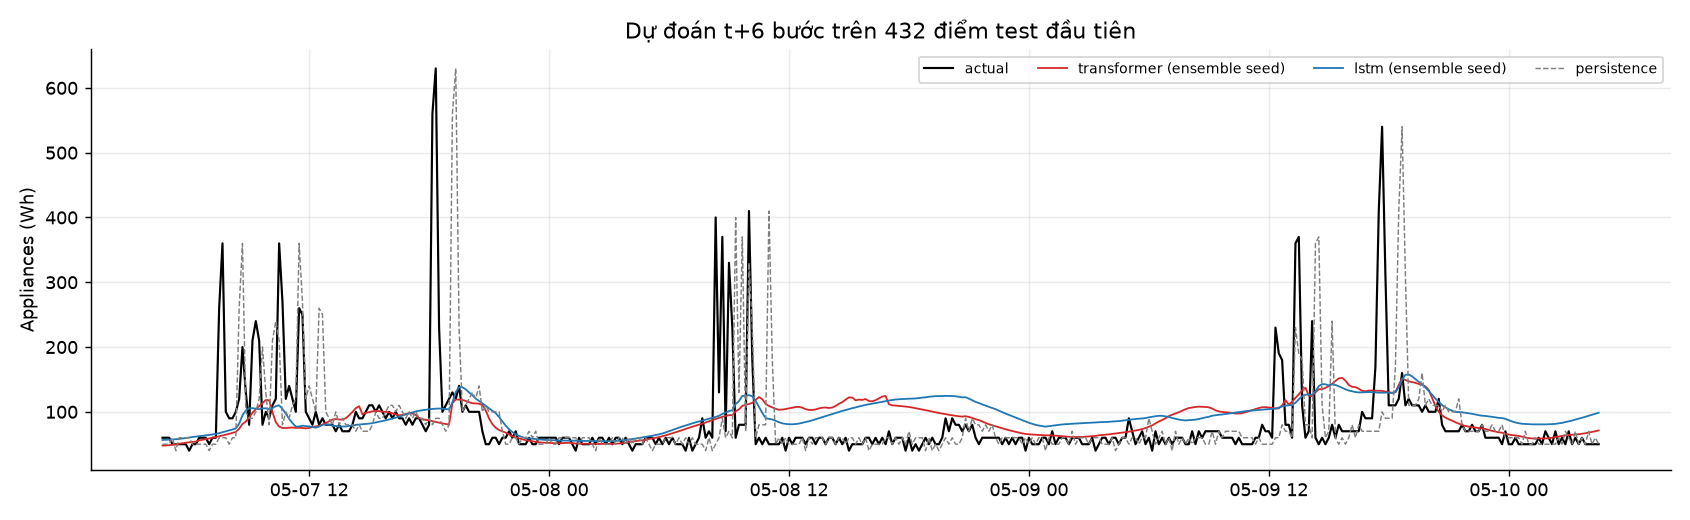

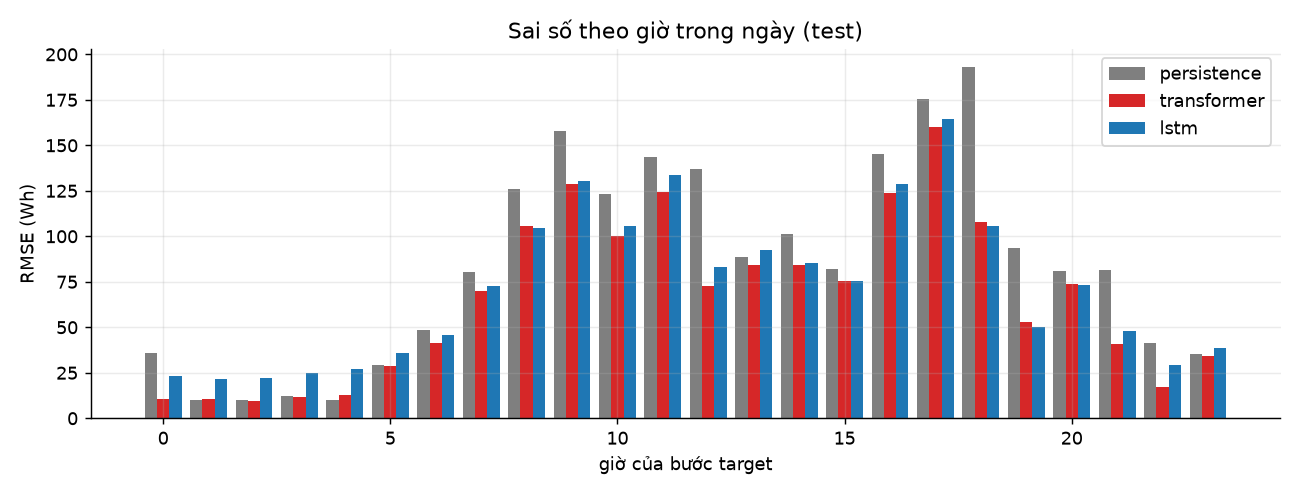

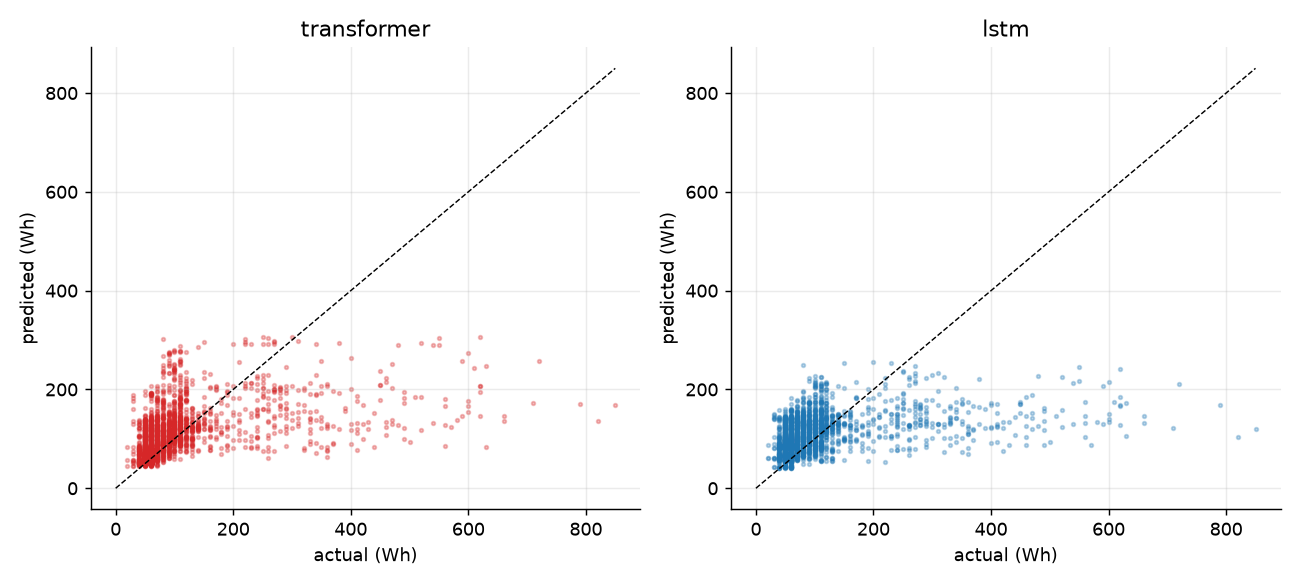

In [16]:
for name in ["pred_vs_actual.png", "error_by_hour.png", "scatter_pred_vs_actual.png"]:
    show_img(OUT / "figures" / name, width=950)

## 7. Phân tích attention map
`python -m src.attention --seed 0`. Attention được lấy từ token `[CLS]` (hàng đầu của ma trận attention) tới các bước thời gian trong window.

**Lưu ý quan trọng:** attention cho biết mô hình *phân bổ trọng số* thế nào, **không phải bằng chứng nhân quả** rằng bước đó là nguyên nhân của dự đoán. Vì vậy ta đối chiếu thêm với permutation importance (xáo trộn từng feature và xem RMSE tăng bao nhiêu).

In [17]:
att = load_json_safe(OUT / "attention" / "attention_summary.json")
if att:
    keys = ["seed", "n_layers", "n_heads", "max_rowsum_error", "check_rows_sum_to_1", "mean_entropy_ratio",
            "min_head_entropy_ratio", "top3_lags_minutes_by_rollout", "last_step_attention_share"]
    display(pd.Series({k: att.get(k) for k in keys}, name="giá trị").to_frame())
else:
    print("(chưa có attention_summary.json)")

,giá trị
seed,0
n_layers,2
n_heads,4
max_rowsum_error,0.0
check_rows_sum_to_1,True
mean_entropy_ratio,0.933122
min_head_entropy_ratio,0.815318
top3_lags_minutes_by_rollout,"[-10, -20, -70]"
last_step_attention_share,0.047866


**Cách đọc các con số:** `max_rowsum_error` rất nhỏ nghĩa là mỗi hàng attention cộng bằng 1, tức trích xuất đúng. `mean_entropy_ratio` gần 1 là attention phân tán đều, gần 0 là tập trung vào vài bước. `top3_lags_minutes_by_rollout` là 3 độ trễ (phút) nhận nhiều attention nhất sau khi tổng hợp qua các layer.

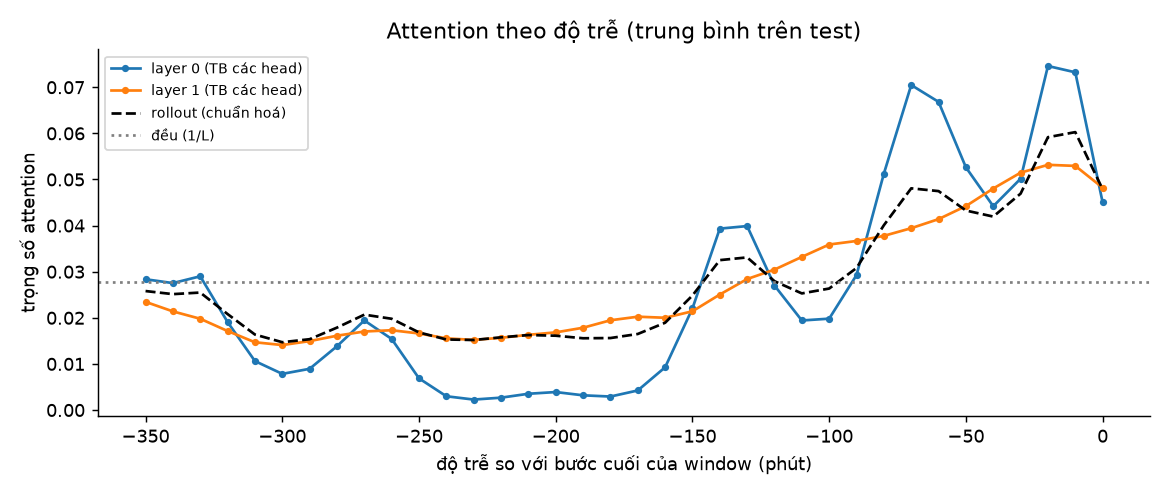

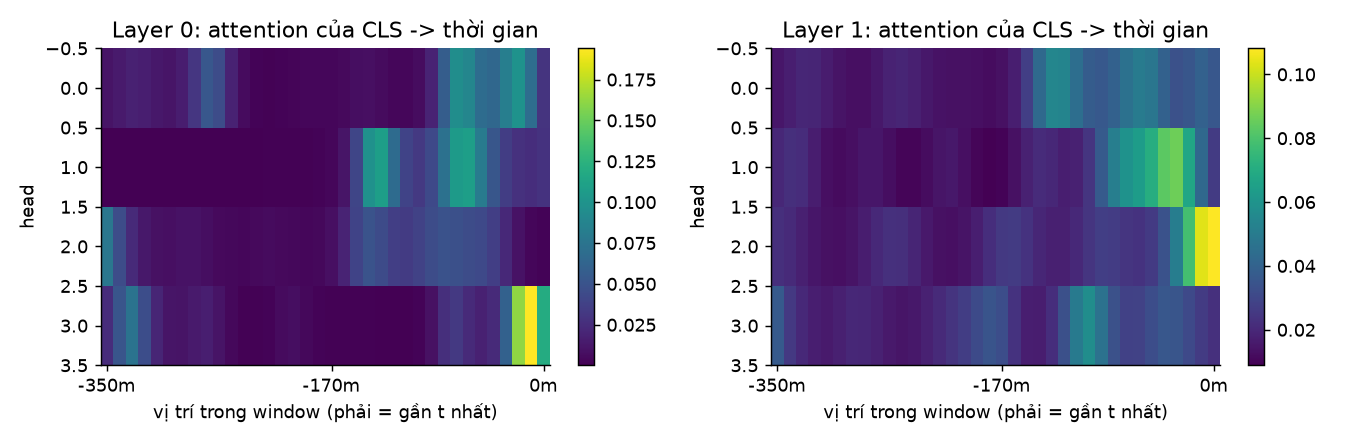

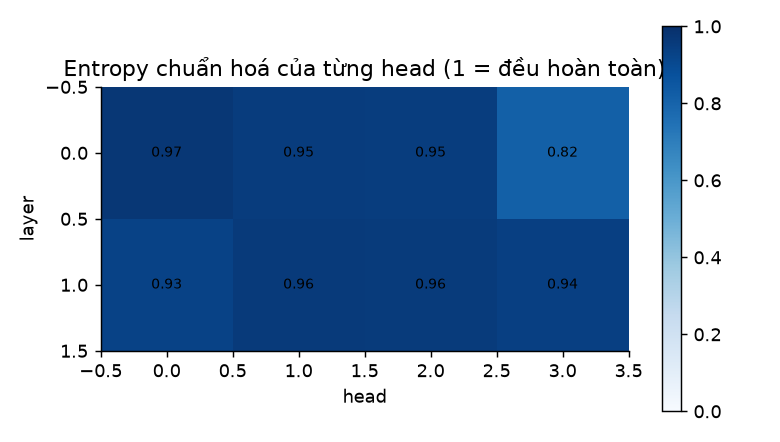

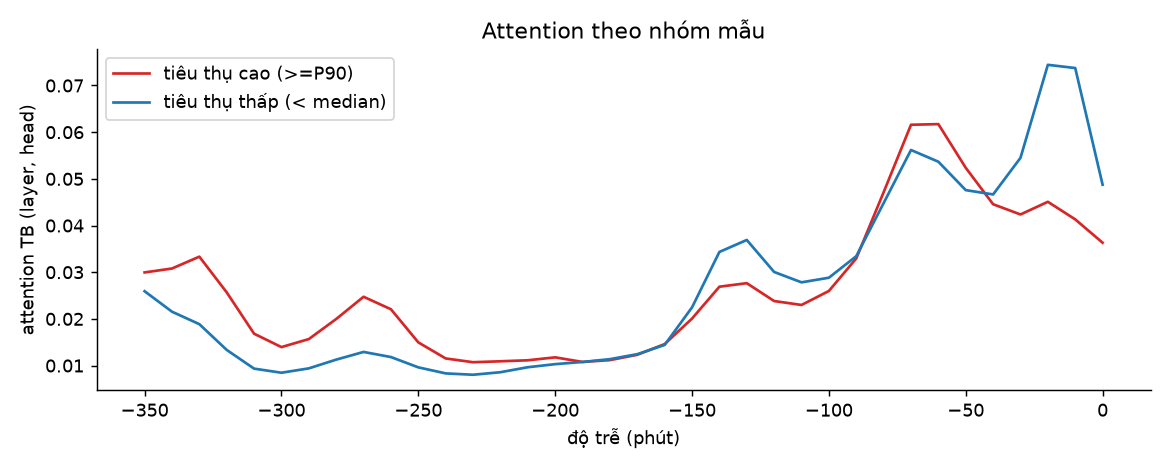

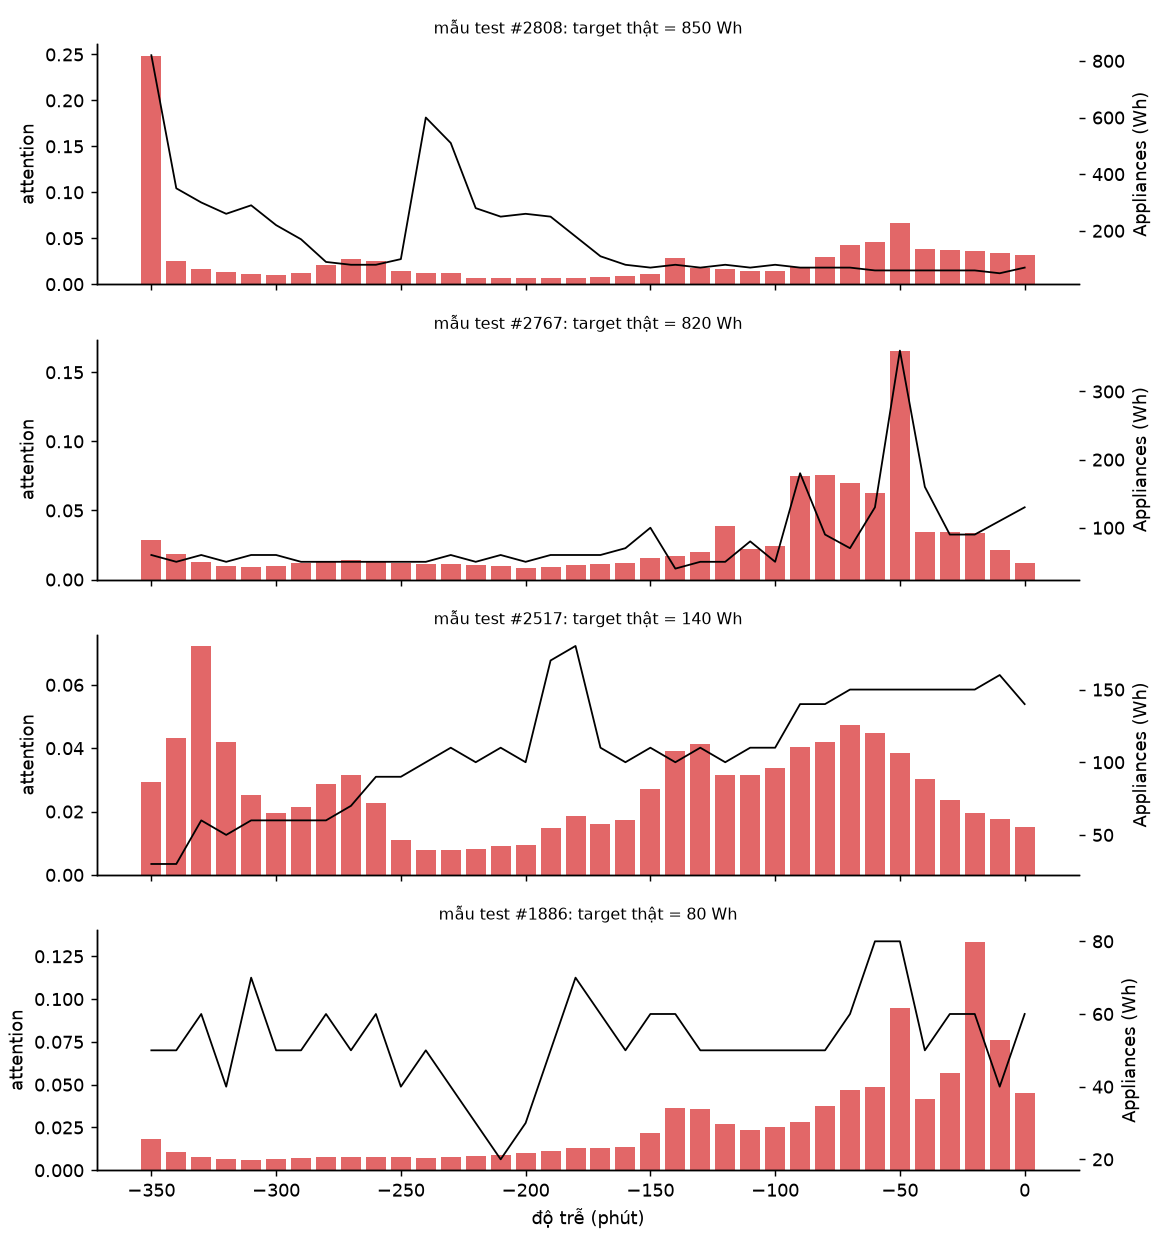

In [18]:
for name in ["attn_by_lag.png", "attn_heads_over_time.png", "attn_entropy.png", "attn_high_vs_low.png", "attn_examples.png"]:
    show_img(OUT / "attention" / name, width=900)

Top 10 feature theo permutation importance của Transformer (tăng RMSE, đơn vị Wh, khi xáo trộn feature):


,feature,transformer_delta_rmse,transformer_std,lstm_delta_rmse,lstm_std
27,hour_cos,10.586,0.616,4.119,0.222
0,Appliances,8.816,0.303,7.275,0.037
26,hour_sin,1.622,0.025,0.843,0.226
11,RH_5,1.018,0.137,1.506,0.199
9,RH_4,0.969,0.145,-0.907,0.029
25,Tdewpoint,0.829,0.122,-0.569,0.048
15,RH_7,0.791,0.125,-0.238,0.065
28,dow_sin,0.755,0.141,0.504,0.033
2,T1,0.729,0.247,0.252,0.245
22,RH_out,0.653,0.373,-0.078,0.136


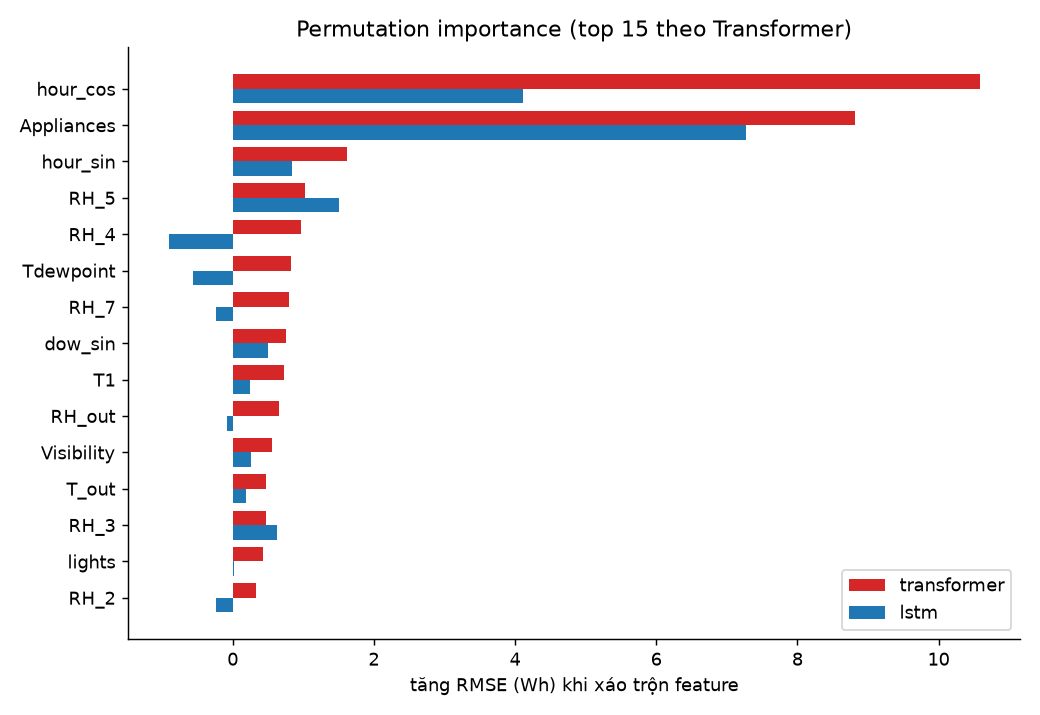

In [19]:
pi = OUT / "attention" / "permutation_importance.csv"
if pi.exists():
    df = pd.read_csv(pi)
    key = "transformer_delta_rmse" if "transformer_delta_rmse" in df else df.columns[1]
    print("Top 10 feature theo permutation importance của Transformer (tăng RMSE, đơn vị Wh, khi xáo trộn feature):")
    display(df.sort_values(key, ascending=False).head(10).round(3))
show_img(OUT / "attention" / "permutation_importance.png", width=800)

## 7b. Ablation D21: bỏ nhóm nhiệt độ
Test rơi vào giai đoạn ấm hơn train (nhiệt độ lệch +2 đến +3 độ lệch chuẩn) trong khi nhiệt độ chỉ tương quan yếu với target. Để kiểm tra mô hình có bị thiệt vì ngoại suy trên nhiệt độ không, ta huấn luyện lại **không dùng** `T1`–`T9`, `T_out`, `Tdewpoint` (11 cột; còn 20 feature) rồi so sánh. Cấu hình chính vẫn chọn theo **val**; test chỉ để báo cáo. Chi tiết: `doc/14_ablation_no_temperature.md`.

In [20]:
ABL = OUT.parent / "outputs_no_temp"
if (ABL / "ablation_comparison.md").exists():
    show_md(ABL / "ablation_comparison.md")
    show_img(ABL / "ablation_comparison.png", width=900)
else:
    print("(chưa chạy ablation. Chạy scripts/run_ablation_no_temp.ps1 rồi chạy lại ô này)")

(chưa chạy ablation. Chạy scripts/run_ablation_no_temp.ps1 rồi chạy lại ô này)


## 8. Kết luận
Các câu dưới đây được tính tự động từ kết quả hiện có.

In [21]:
sm = OUT / "metrics" / "summary.csv"
if sm.exists():
    df = pd.read_csv(sm).set_index("model")
    def r(m): return float(df.loc[m, "rmse_mean"]) if m in df.index else None
    t, l, ri, mv, ps = r("transformer"), r("lstm"), r("ridge"), r("moving_avg_6"), r("persistence")
    te = r("transformer_seed_ensemble")
    print(f"- RMSE test (Wh): Transformer {t:.2f}, LSTM {l:.2f}, Ridge {ri:.2f}, moving_avg_6 {mv:.2f}, persistence {ps:.2f}.")
    if t is not None and ri is not None:
        print(f"- Một mô hình Transformer đơn lẻ {'THẮNG' if t < ri else 'KHÔNG thắng'} Ridge ở điểm ước lượng (chênh {t - ri:+.2f} Wh).")
    if te is not None and ri is not None:
        print(f"- Ensemble 3 seed của Transformer: {te:.2f} Wh ({te - ri:+.2f} so với Ridge), nhưng so sánh này có lợi cho ensemble.")
    if t is not None and l is not None:
        print(f"- Transformer {'tốt hơn' if t < l else 'không tốt hơn'} LSTM {abs(t - l):.2f} Wh (xem bảng bootstrap để biết có ý nghĩa thống kê không).")
    r2 = float(df.loc[[m for m in ["transformer_seed_ensemble", "transformer"] if m in df.index][0], "r2_mean"])
    print(f"- R² tốt nhất của Transformer là {r2:.2f}: phần lớn phương sai vẫn chưa giải thích được.")
ck = load_json_safe(OUT / "metrics" / "success_checks.json")
if ck:
    n_pass = sum(c["pass"] for c in ck)
    print(f"- Tiêu chí thành công: {n_pass} PASS / {len(ck) - n_pass} FAIL (danh sách ở mục 6).")

- RMSE test (Wh): Transformer 82.39, LSTM 87.52, Ridge 81.72, moving_avg_6 88.26, persistence 101.66.
- Một mô hình Transformer đơn lẻ KHÔNG thắng Ridge ở điểm ước lượng (chênh +0.67 Wh).
- Ensemble 3 seed của Transformer: 79.72 Wh (-2.00 so với Ridge), nhưng so sánh này có lợi cho ensemble.
- Transformer tốt hơn LSTM 5.13 Wh (xem bảng bootstrap để biết có ý nghĩa thống kê không).
- R² tốt nhất của Transformer là 0.23: phần lớn phương sai vẫn chưa giải thích được.
- Tiêu chí thành công: 11 PASS / 5 FAIL (danh sách ở mục 6).


**Diễn giải trung thực**
- Transformer **tốt hơn LSTM** và hơn các baseline đơn giản (persistence, moving average) có ý nghĩa thống kê, nhưng **chưa vượt được Ridge một cách chắc chắn**. Chênh lệch với Ridge nhỏ hơn dao động giữa các seed.
- Điều này không có nghĩa là mô hình sai. Dự đoán tiêu thụ điện của một hộ gia đình sau 1 giờ có rất nhiều thành phần ngẫu nhiên (thời điểm bật thiết bị), nên trần R² thấp. Một mô hình tuyến tính đã khai thác gần hết phần dự đoán được.
- Attention của Transformer có cấu trúc (không đều tuyệt đối) nhưng khá phân tán. Cần cẩn thận khi diễn giải: attention không phải giải thích nhân quả.

**Hạn chế**
1. Test rơi vào giai đoạn ấm hơn train (nhiệt độ lệch khoảng +2 đến +3 độ lệch chuẩn), nên kết quả test phản ánh cả khả năng ngoại suy.
2. Chỉ một lần chia train/val/test; chưa có rolling-origin validation.
3. Chỉ 3 seed; khoảng tin cậy bootstrap tính trên một đoạn test duy nhất.
4. `log1p` có thể làm dự đoán thấp hơn ở các đỉnh khi quy ngược về Wh (MAE và MAPE của Transformer kém một số baseline dù RMSE tốt hơn).
5. Attention và permutation importance chỉ tính cho seed 0.

**Việc có thể làm tiếp:** so sánh `log1p` với không biến đổi; thử `lookback = 144` để xem attention có chú ý tới lag 1 ngày không; rolling-origin validation.

## 9. Câu hỏi hay gặp khi bảo vệ

**Vì sao chia theo thời gian mà không shuffle?** Dữ liệu là chuỗi thời gian. Nếu shuffle thì cửa sổ của tập train và test chồng lấn nhau theo thời gian, mô hình "nhìn thấy tương lai" và kết quả đẹp một cách giả tạo.

**Vì sao fit scaler chỉ trên train?** Nếu tính trung bình và độ lệch chuẩn trên cả dữ liệu thì thông tin của val và test rò rỉ vào quá trình huấn luyện.

**Early stopping hoạt động thế nào và vì sao dùng val chứ không dùng test?** Mô hình dừng khi val RMSE không cải thiện 12 epoch liên tiếp, và lấy checkpoint ở epoch tốt nhất trên val. Test chỉ được dùng một lần để báo cáo; nếu dùng test để chọn mô hình thì kết quả test không còn khách quan.

**Vì sao Ridge mạnh như vậy?** Dữ liệu ít (khoảng 14.000 cửa sổ train), tín hiệu yếu và nhiễu lớn. Với điều kiện đó, mô hình đơn giản ít bị overfit thường cạnh tranh được với mô hình lớn.

**Vì sao chạy 3 seed?** Một lần chạy có thể may hoặc xui do khởi tạo ngẫu nhiên. Báo cáo mean ± std và kiểm định bootstrap giúp biết chênh lệch có thật hay chỉ là ngẫu nhiên.

**Attention có cho biết mô hình "giải thích" dự đoán thế nào không?** Không hẳn. Attention chỉ cho biết trọng số phân bổ, không chứng minh nhân quả. Vì vậy có thêm permutation importance để đối chiếu.

**Vì sao dùng `log1p` cho target?** Target lệch phải rất mạnh. Biến đổi log giúp huấn luyện ổn định hơn, nhưng đổi lại có thể làm dự đoán ở các đỉnh bị thấp đi khi quy về Wh.